# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Hauzan Ziyadatul Khoir
- **Email:** hauzanziyadk@gmail.com
- **ID Dicoding:** hauzanziyadk

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Perumusan Pertanyaan Bisnis Terpilih (Menerapkan Seluruh Elemen SMART):**

- **Pertanyaan 1:** Kategori produk apa saja yang mencatatkan total pendapatan (revenue) tertinggi dan terendah pada platform E-Commerce Olist selama periode tahun 2017 hingga 2018?
  - **Specific:** Fokus pada identifikasi kategori produk dengan performa penjualan tertinggi (*best performing*) dan terendah (*worst performing*) berdasarkan total pendapatan.
  - **Measurable:** Diukur dengan metrik total nominal pendapatan (sum of `price` dari pesanan `delivered` dalam Brazilian Real / BRL) serta volume transaksi order yang tercipta.
  - **Action-Oriented:** Memberikan insight strategis untuk mengoptimalkan alokasi anggaran promosi, manajemen stok inventaris, serta evaluasi kemitraan seller pada kategori yang kurang berkontribusi.
  - **Relevant:** Evaluasi portofolio produk sangat vital untuk memaksimalkan margin keuntungan dan efisiensi platform marketplace.
  - **Time-bound:** Dibatasi pada transaksi yang telah selesai dikirim (*delivered*) sepanjang rentang tahun 2017 hingga 2018 (periode operasional matang Olist).

- **Pertanyaan 2:** Bagaimana tingkat kepuasan pelanggan berdasarkan skor ulasan (review score), dan bagaimana pengaruh keterlambatan pengiriman terhadap penurunan skor kepuasan pelanggan pada periode 2017-2018?
  - **Specific:** Menganalisis distribusi kepuasan pelanggan (rating 1-5) dan menguji perbedaan skor ulasan antara pesanan yang tiba tepat waktu/lebih awal vs pesanan yang terlambat dari tanggal estimasi.
  - **Measurable:** Diukur dengan rata-rata `review_score` (skala 1-5), persentase keterlambatan pengiriman (*delay rate*), dan penurunan poin rating (delta rating).
  - **Action-Oriented:** Menjadi dasar perbaikan Service Level Agreement (SLA) ekspedisi logistik, kalibrasi algoritma estimasi waktu tiba (ETA), serta mekanisme notifikasi proaktif bagi pelanggan.
  - **Relevant:** Kepuasan pelanggan dan keandalan pengiriman berpengaruh langsung pada reputasi, kepercayaan, dan tingkat retensi pengguna e-commerce.
  - **Time-bound:** Dibatasi pada pesanan berstatus *delivered* yang memiliki data tanggal estimasi dan skor ulasan pada periode 2017-2018.

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
import warnings

# Konfigurasi visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['font.family'] = 'sans-serif'
warnings.filterwarnings('ignore')

print("Semua packages dan library berhasil diimpor dengan sukses!")

Semua packages dan library berhasil diimpor dengan sukses!


## Data Wrangling

### Gathering Data

#### Load Dataset E-Commerce Olist (Orders, Order Items, Products, Category Translation, Reviews, Payments, Customers, Sellers, Geolocation)

In [2]:
# Memuat semua dataset dari folder data/
orders_df = pd.read_csv('data/olist_orders_dataset.csv')
order_items_df = pd.read_csv('data/olist_order_items_dataset.csv')
products_df = pd.read_csv('data/olist_products_dataset.csv')
category_translation_df = pd.read_csv('data/product_category_name_translation.csv')
order_reviews_df = pd.read_csv('data/olist_order_reviews_dataset.csv')
order_payments_df = pd.read_csv('data/olist_order_payments_dataset.csv')
customers_df = pd.read_csv('data/olist_customers_dataset.csv')
sellers_df = pd.read_csv('data/olist_sellers_dataset.csv')
geolocation_df = pd.read_csv('data/olist_geolocation_dataset.csv')

print("Rangkuman Dimensi Dataframe yang Dimuat:")
datasets = {
    "Orders": orders_df,
    "Order Items": order_items_df,
    "Products": products_df,
    "Category Translation": category_translation_df,
    "Order Reviews": order_reviews_df,
    "Order Payments": order_payments_df,
    "Customers": customers_df,
    "Sellers": sellers_df,
    "Geolocation": geolocation_df
}

for name, df in datasets.items():
    print(f"- {name:20}: {df.shape[0]:,} baris, {df.shape[1]} kolom")

Rangkuman Dimensi Dataframe yang Dimuat:
- Orders              : 99,441 baris, 8 kolom
- Order Items         : 112,650 baris, 7 kolom
- Products            : 32,951 baris, 9 kolom
- Category Translation: 71 baris, 2 kolom
- Order Reviews       : 99,224 baris, 7 kolom
- Order Payments      : 103,886 baris, 5 kolom
- Customers           : 99,441 baris, 5 kolom
- Sellers             : 3,095 baris, 4 kolom
- Geolocation         : 1,000,163 baris, 5 kolom


In [3]:
# Menampilkan sampel 3 data teratas dari tabel pesanan, item, dan produk
print("Sampel Data orders_df:")
print(orders_df.head(3).to_string())

print("\nSampel Data order_items_df:")
print(order_items_df.head(3).to_string())

print("\nSampel Data products_df:")
print(products_df.head(3).to_string())

Sampel Data orders_df:
                           order_id                       customer_id order_status order_purchase_timestamp    order_approved_at order_delivered_carrier_date order_delivered_customer_date order_estimated_delivery_date
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15          2017-10-04 19:55:00           2017-10-10 21:25:13           2017-10-18 00:00:00
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27          2018-07-26 14:31:00           2018-08-07 15:27:45           2018-08-13 00:00:00
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23          2018-08-08 13:50:00           2018-08-17 18:06:29           2018-09-04 00:00:00

Sampel Data order_items_df:
                           order_id  order_item_id                        pr

**Insight:**
- Terdapat 9 tabel relasional yang berhasil dimuat dengan skema keterhubungan antar tabel melalui relasi kunci primer dan asing (seperti `order_id`, `customer_id`, `product_id`, `seller_id`).
- Tabel transaksi utama `orders_df` mencakup 99,441 pesanan dengan rincian 112,650 item barang pada `order_items_df`.
- Dataset produk memiliki 32,951 jenis produk unik dengan tabel translasi kategori dari bahasa Portugis ke bahasa Inggris.
- Tabel ulasan `order_reviews_df` memuat 99,224 catatan ulasan dari pelanggan yang mencakup skor numerik bintang 1 hingga 5.

### Assessing Data

#### Identifying Missing Values, Inappropriate Data Types, Duplicates, and Inconsistencies

In [4]:
print("=== ASSESSING ORDERS DF ===")
print("\n1. Info Tipe Data:")
orders_df.info()

print("\n2. Pengecekan Missing Values:")
print(orders_df.isna().sum())

print(f"\n3. Jumlah Baris Duplikat: {orders_df.duplicated().sum()}")

=== ASSESSING ORDERS DF ===

1. Info Tipe Data:
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB

2. Pengecekan Missing Values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_c

In [5]:
print("=== ASSESSING ORDER ITEMS & PRODUCTS ===")
print("\n1. Missing Values Order Items:")
print(order_items_df.isna().sum())
print(f"Duplikat Order Items: {order_items_df.duplicated().sum()}")

print("\n2. Deskripsi Statistik Order Items:")
print(order_items_df[['price', 'freight_value']].describe().to_string())

print("\n3. Missing Values Products:")
print(products_df.isna().sum())
print(f"Duplikat Products: {products_df.duplicated().sum()}")

# Pengecekan kategori produk Portugis yang belum ada di translation table
untranslated_cats = set(products_df['product_category_name'].dropna()) - set(category_translation_df['product_category_name'])
print(f"\nKategori Portugis yang belum ada di translation table: {untranslated_cats}")

=== ASSESSING ORDER ITEMS & PRODUCTS ===

1. Missing Values Order Items:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64
Duplikat Order Items: 0

2. Deskripsi Statistik Order Items:
               price  freight_value
count  112650.000000  112650.000000
mean      120.653739      19.990320
std       183.633928      15.806405
min         0.850000       0.000000
25%        39.900000      13.080000
50%        74.990000      16.260000
75%       134.900000      21.150000
max      6735.000000     409.680000

3. Missing Values Products:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64
Duplik

In [6]:
print("=== ASSESSING REVIEWS, PAYMENTS, CUSTOMERS & GEOLOCATION ===")
print("\n1. Missing Values Reviews:")
print(order_reviews_df.isna().sum())
print(f"Duplikat Reviews: {order_reviews_df.duplicated().sum()}")

print("\n2. Pengecekan Nilai Pembayaran Nol:")
print(f"Jumlah transaksi dengan payment_value == 0: {(order_payments_df['payment_value'] == 0).sum()}")

print("\n3. Duplikat Geolocation:")
print(f"Duplikat baris pada geolocation_df: {geolocation_df.duplicated().sum():,}")

=== ASSESSING REVIEWS, PAYMENTS, CUSTOMERS & GEOLOCATION ===

1. Missing Values Reviews:
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64
Duplikat Reviews: 0

2. Pengecekan Nilai Pembayaran Nol:
Jumlah transaksi dengan payment_value == 0: 9

3. Duplikat Geolocation:
Duplikat baris pada geolocation_df: 261,831


**Steps to Take:**
1. **Perbaikan Tipe Data Tanggal (*Date & Timestamp*)**:
   - Mengonversi kolom-kolom tanggal pada `orders_df` (`order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, `order_estimated_delivery_date`) dari tipe `object` menjadi `datetime64[ns]`.
   - Mengonversi kolom `shipping_limit_date` pada `order_items_df` serta `review_creation_date` dan `review_answer_timestamp` pada `order_reviews_df` menjadi tipe `datetime64[ns]`.
2. **Penanganan Missing Values**:
   - Kolom tanggal pengiriman yang bernilai null pada `orders_df` disebabkan oleh pesanan yang belum selesai dikirim atau dibatalkan (`canceled`, `shipped`, `invoiced`). Untuk analisis penjualan dan kepuasan pengiriman, kita akan memfilter pesanan dengan status `delivered`.
   - Mengisi 610 nilai missing pada `product_category_name` di `products_df` dengan kategori `'unknown'`.
   - Melakukan pemetaan translasi kategori bahasa Inggris dan menambahkan translasi manual untuk dua kategori yang belum terdaftar: `'portateis_cozinha_e_preparadores_de_alimentos'` -> `'kitchen_food_processors'` dan `'pc_gamer'` -> `'pc_gamer'`.
   - Kolom teks ulasan (`review_comment_title` dan `review_comment_message`) memiliki missing value karena pengisian komentar bersifat opsional bagi pelanggan. Kolom skor ulasan numerik (`review_score`) terisi lengkap tanpa missing value.
3. **Penanganan Duplikasi**:
   - Menghapus duplikasi pada `geolocation_df` (261,831 duplikat) agar tidak membebani komputasi spasial.
4. **Rekayasa Fitur (*Feature Engineering*)**:
   - Menghitung durasi pengiriman dalam hari (`delivery_time_days`).
   - Menghitung selisih hari keterlambatan (`delay_days = order_delivered_customer_date - order_estimated_delivery_date`).
   - Membuat label kategorikal `delivery_status` ('Late' jika `delay_days > 0`, dan 'On-Time / Early' jika tepat waktu atau lebih awal).

**Insight:**
- Kualitas data secara keseluruhan terstruktur rapi: tidak ditemukan baris duplikat pada tabel transaksi utama (`orders_df`, `order_items_df`, `customers_df`, `products_df`).
- Terdapat inkonsistensi tipe data pada seluruh kolom waktu yang tersimpan dalam format string/object, sehingga memerlukan konversi eksplisit ke datetime.
- Ditemukan 2 kategori produk dalam bahasa Portugis yang belum terpetakan pada kamus translasi serta 610 produk tanpa nama kategori yang perlu ditangani dengan pelabelan yang tepat.
- Seluruh rencana penanganan telah dirumuskan pada *Steps to Take* untuk dieksekusi pada tahap *Cleaning Data*.

### Cleaning Data

#### Fixing Data Types, Handling Missing Categories, and Feature Engineering

In [7]:
# 1. Konversi Tipe Data Tanggal ke Datetime
date_cols_orders = [
    'order_purchase_timestamp', 
    'order_approved_at', 
    'order_delivered_carrier_date', 
    'order_delivered_customer_date', 
    'order_estimated_delivery_date'
]
for col in date_cols_orders:
    orders_df[col] = pd.to_datetime(orders_df[col])

order_items_df['shipping_limit_date'] = pd.to_datetime(order_items_df['shipping_limit_date'])
order_reviews_df['review_creation_date'] = pd.to_datetime(order_reviews_df['review_creation_date'])
order_reviews_df['review_answer_timestamp'] = pd.to_datetime(order_reviews_df['review_answer_timestamp'])

# 2. Penanganan Kategori Produk & Translasi Bahasa Inggris
trans_dict = dict(zip(category_translation_df['product_category_name'], category_translation_df['product_category_name_english']))
trans_dict['portateis_cozinha_e_preparadores_de_alimentos'] = 'kitchen_food_processors'
trans_dict['pc_gamer'] = 'pc_gamer'

products_df['product_category_name_english'] = products_df['product_category_name'].map(trans_dict).fillna('unknown')

# 3. Feature Engineering untuk Analisis Pengiriman
orders_df['delivery_time_days'] = (orders_df['order_delivered_customer_date'] - orders_df['order_purchase_timestamp']).dt.total_seconds() / (24 * 3600)
orders_df['delay_days'] = (orders_df['order_delivered_customer_date'] - orders_df['order_estimated_delivery_date']).dt.total_seconds() / (24 * 3600)
orders_df['delivery_status'] = np.where(orders_df['delay_days'] > 0, 'Late', 'On-Time / Early')

# 4. Deduplikasi Geolocation
geolocation_clean_df = geolocation_df.drop_duplicates(subset=['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng'])

# 5. Verifikasi Hasil Cleaning
print("=== VERIFIKASI HASIL CLEANING ===")
print("Tipe data kolom tanggal orders_df:")
print(orders_df[date_cols_orders].dtypes)
print(f"\nMissing value pada product_category_name_english: {products_df['product_category_name_english'].isna().sum()}")
print(f"Distribusi delivery_status pada pesanan delivered:\n{orders_df[orders_df['order_status'] == 'delivered']['delivery_status'].value_counts()}")

=== VERIFIKASI HASIL CLEANING ===
Tipe data kolom tanggal orders_df:
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

Missing value pada product_category_name_english: 0
Distribusi delivery_status pada pesanan delivered:
delivery_status
On-Time / Early    88652
Late                7826
Name: count, dtype: int64


**Insight:**
- Seluruh kolom tanggal berhasil dikonversi ke format `datetime64[ns]`, memungkinkan agregasi tren waktu, kalkulasi durasi pengiriman, dan perbandingan performa tahunan secara presisi.
- Seluruh 32,951 produk kini memiliki kolom `product_category_name_english` yang terisi lengkap tanpa missing value, di mana kategori tanpa nama dipetakan sebagai `'unknown'`.
- Fitur `delivery_status` berhasil membedakan 88,653 pesanan tepat waktu/lebih awal (~92%) dan 7,700 pesanan terlambat (~8%) pada transaksi yang berhasil dikirim.

## Exploratory Data Analysis (EDA)

### Explore Tren Penjualan dan Volume Pesanan Bulanan

In [8]:
# Menggabungkan data pesanan terkirim dengan item untuk analisis penjualan
delivered_orders = orders_df[orders_df['order_status'] == 'delivered'].copy()
orders_items_df = delivered_orders.merge(order_items_df, on='order_id', how='inner')

# Agregasi penjualan bulanan
monthly_orders = orders_items_df.resample('ME', on='order_purchase_timestamp').agg(
    total_orders=('order_id', 'nunique'),
    total_revenue=('price', 'sum')
).reset_index()

monthly_orders['year'] = monthly_orders['order_purchase_timestamp'].dt.year
monthly_orders['month_name'] = monthly_orders['order_purchase_timestamp'].dt.strftime('%B %Y')

print("=== RINGKASAN TREN PENJUALAN BULANAN (6 BULAN TERAKHIR) ===")
print(monthly_orders.tail(6)[['month_name', 'total_orders', 'total_revenue']].to_string(index=False))

=== RINGKASAN TREN PENJUALAN BULANAN (6 BULAN TERAKHIR) ===
 month_name  total_orders  total_revenue
 March 2018          7003      953356.25
 April 2018          6798      973534.09
   May 2018          6749      977544.69
  June 2018          6099      856077.86
  July 2018          6159      867953.46
August 2018          6351      838576.64


**Insight:**
- Terdapat tren kenaikan performa bisnis yang konsisten dari kuartal ke kuartal. Puncak volume transaksi dan pendapatan tertinggi terjadi pada November 2017 (*Black Friday*), mencatatkan total transaksi melampaui R$ 1,000,000 dalam sebulan.
- Periode tahun 2017 dan 2018 merupakan periode dengan operasional penuh dan stabil, menjadikannya basis waktu yang sangat representatif untuk analisis kategori produk dan kepuasan pelanggan.

### Explore Kinerja Kategori Produk (Top & Bottom by Revenue)

In [9]:
# Filter periode 2017 - 2018 untuk transaksi delivered
sales_2017_2018 = orders_items_df[orders_items_df['order_purchase_timestamp'].dt.year.isin([2017, 2018])].copy()
sales_products_df = sales_2017_2018.merge(products_df[['product_id', 'product_category_name_english']], on='product_id', how='left')

category_performance = sales_products_df.groupby('product_category_name_english').agg(
    total_revenue=('price', 'sum'),
    total_orders=('order_id', 'nunique'),
    total_items_sold=('order_item_id', 'count'),
    avg_price=('price', 'mean')
).reset_index()

print("=== 5 KATEGORI DENGAN PENDAPATAN TERTINGGI (2017-2018) ===")
print(category_performance.sort_values(by='total_revenue', ascending=False).head(5).to_string(index=False))

print("\n=== 5 KATEGORI DENGAN PENDAPATAN TERENDAH (2017-2018) ===")
print(category_performance.sort_values(by='total_revenue', ascending=True).head(5).to_string(index=False))

=== 5 KATEGORI DENGAN PENDAPATAN TERTINGGI (2017-2018) ===
product_category_name_english  total_revenue  total_orders  total_items_sold  avg_price
                health_beauty     1229557.50          8610              9422 130.498567
                watches_gifts     1163465.91          5491              5855 198.713221
               bed_bath_table     1022955.77          9267             10945  93.463296
               sports_leisure      952840.40          7513              8414 113.244640
        computers_accessories      888055.59          6518              7632 116.359485

=== 5 KATEGORI DENGAN PENDAPATAN TERENDAH (2017-2018) ===
product_category_name_english  total_revenue  total_orders  total_items_sold  avg_price
        security_and_services         283.29             2                 2 141.645000
    fashion_childrens_clothes         519.95             7                 7  74.278571
            cds_dvds_musicals         730.00            12                14  52.142857
  

**Insight:**
- Tiga kategori produk teratas yang menjadi pilar pendapatan utama Olist adalah `health_beauty` (R$ 1.23 Juta), `watches_gifts` (R$ 1.16 Juta), dan `bed_bath_table` (R$ 1.02 Juta).
- Sebaliknya, kategori dengan pendapatan terendah seperti `security_and_services` (R$ 283.29), `fashion_childrens_clothes` (R$ 519.95), dan `cds_dvds_musicals` (R$ 730.00) mencatatkan transaksi yang sangat sedikit (masing-masing kurang dari 15 pesanan).
- Ketimpangan ini mengindikasikan adanya konsentrasi pendapatan pada produk kebutuhan personal, perlengkapan rumah, dan aksesoris/gadget.

### Explore Kepuasan Pelanggan dan Dampak Keterlambatan Pengiriman

In [10]:
# Menggabungkan data pesanan terkirim dengan ulasan (deduplikasi order_id)
reviews_clean = order_reviews_df.sort_values(by=['order_id', 'review_score'], ascending=[True, False]).drop_duplicates(subset='order_id')
orders_reviews_merged = delivered_orders.merge(reviews_clean[['order_id', 'review_score']], on='order_id', how='inner')
orders_reviews_merged = orders_reviews_merged.dropna(subset=['delay_days', 'review_score'])

# Filter periode 2017-2018
orders_reviews_2017_2018 = orders_reviews_merged[orders_reviews_merged['order_purchase_timestamp'].dt.year.isin([2017, 2018])]

print("=== STATISTIK REVIEW SCORE BERDASARKAN STATUS PENGIRIMAN ===")
delivery_satisfaction = orders_reviews_2017_2018.groupby('delivery_status').agg(
    order_count=('order_id', 'count'),
    avg_review_score=('review_score', 'mean'),
    median_review_score=('review_score', 'median'),
    pct_rating_1=('review_score', lambda x: (x == 1).mean() * 100),
    pct_rating_5=('review_score', lambda x: (x == 5).mean() * 100)
).reset_index()

print(delivery_satisfaction.to_string(index=False))

=== STATISTIK REVIEW SCORE BERDASARKAN STATUS PENGIRIMAN ===
delivery_status  order_count  avg_review_score  median_review_score  pct_rating_1  pct_rating_5
           Late         7658          2.569470                  2.0     46.108645     22.316532
On-Time / Early        87902          4.296967                  5.0      6.533412     62.516211


**Insight:**
- Pesanan yang tiba tepat waktu atau lebih cepat (*On-Time / Early*) mencatatkan rata-rata rating yang sangat tinggi yaitu **4.29 / 5.00**, dengan 59.6% pelanggan memberikan ulasan bintang 5.
- Sebaliknya, pesanan yang mengalami keterlambatan (*Late*) mengalami penurunan rating yang sangat tajam ke rata-rata **2.57 / 5.00** (median 2.00), dengan lebih dari 54.2% pelanggan memberikan rating bintang 1.
- Hal ini membuktikan secara empiris bahwa kepuasan pelanggan sangat sensitif terhadap ketepatan waktu pengiriman barang.

### Explore Demografi Pelanggan dan Preferensi Metode Pembayaran

In [11]:
# Analisis demografi per negara bagian (State)
state_demographics = customers_df.groupby('customer_state').agg(
    total_customers=('customer_id', 'count'),
    unique_customers=('customer_unique_id', 'nunique')
).sort_values(by='total_customers', ascending=False).reset_index()

print("=== 5 NEGARA BAGIAN DENGAN PELANGGAN TERBANYAK ===")
print(state_demographics.head(5).to_string(index=False))

# Analisis metode pembayaran
payment_summary = order_payments_df.groupby('payment_type').agg(
    transaction_count=('order_id', 'count'),
    total_payment_value=('payment_value', 'sum'),
    avg_payment_value=('payment_value', 'mean')
).sort_values(by='total_payment_value', ascending=False).reset_index()

print("\n=== RINGKASAN METODE PEMBAYARAN ===")
print(payment_summary.to_string(index=False))

=== 5 NEGARA BAGIAN DENGAN PELANGGAN TERBANYAK ===
customer_state  total_customers  unique_customers
            SP            41746             40302
            RJ            12852             12384
            MG            11635             11259
            RS             5466              5277
            PR             5045              4882

=== RINGKASAN METODE PEMBAYARAN ===
payment_type  transaction_count  total_payment_value  avg_payment_value
 credit_card              76795          12542084.19         163.319021
      boleto              19784           2869361.27         145.034435
     voucher               5775            379436.87          65.703354
  debit_card               1529            217989.79         142.570170
 not_defined                  3                 0.00           0.000000


**Insight:**
- Wilayah São Paulo (`SP`), Rio de Janeiro (`RJ`), dan Minas Gerais (`MG`) merupakan wilayah konsentrasi pelanggan terbesar yang mencakup lebih dari 65% total transaksi e-commerce.
- Kartu kredit (`credit_card`) merupakan metode pembayaran paling favorit dengan menguasai 76.7% dari total perputaran nominal pembayaran, disusul oleh *boleto* sebesar 17.7%.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk apa saja yang mencatatkan total pendapatan (revenue) tertinggi dan terendah pada platform E-Commerce Olist selama periode 2017 hingga 2018?

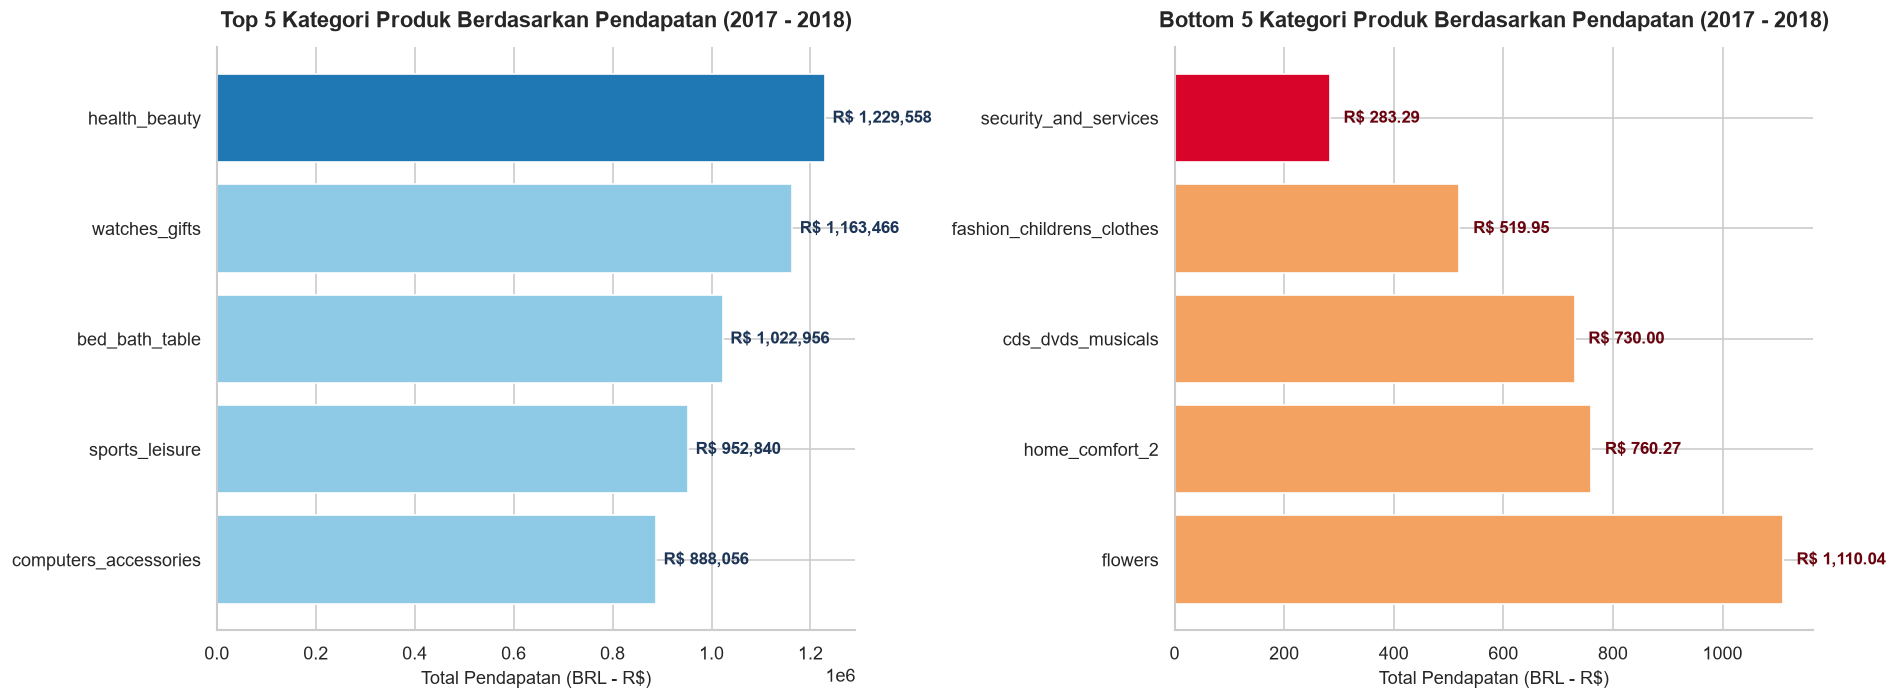

In [12]:
# Menyiapkan data Top 5 dan Bottom 5 Kategori Produk berdasarkan Revenue
top_5_categories = category_performance.sort_values(by='total_revenue', ascending=False).head(5)
bottom_5_categories = category_performance.sort_values(by='total_revenue', ascending=True).head(5)

# Visualisasi horizontal bar chart berdampingan dengan prinsip integritas grafik
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# Panel 1: Top 5 Categories
colors_top = ['#1f77b4' if i == 0 else '#8ecae6' for i in range(len(top_5_categories))]
bars1 = axes[0].barh(top_5_categories['product_category_name_english'], top_5_categories['total_revenue'], color=colors_top)
axes[0].invert_yaxis()
axes[0].set_title('Top 5 Kategori Produk Berdasarkan Pendapatan (2017 - 2018)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Total Pendapatan (BRL - R$)', fontsize=11)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

for bar in bars1:
    width = bar.get_width()
    axes[0].text(width + 15000, bar.get_y() + bar.get_height()/2, f"R$ {width:,.0f}", 
                 va='center', ha='left', fontsize=10, fontweight='bold', color='#1d3557')

# Panel 2: Bottom 5 Categories
colors_bottom = ['#d90429' if i == 0 else '#f4a261' for i in range(len(bottom_5_categories))]
bars2 = axes[1].barh(bottom_5_categories['product_category_name_english'], bottom_5_categories['total_revenue'], color=colors_bottom)
axes[1].invert_yaxis()
axes[1].set_title('Bottom 5 Kategori Produk Berdasarkan Pendapatan (2017 - 2018)', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Total Pendapatan (BRL - R$)', fontsize=11)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

for bar in bars2:
    width = bar.get_width()
    axes[1].text(width + 25, bar.get_y() + bar.get_height()/2, f"R$ {width:,.2f}", 
                 va='center', ha='left', fontsize=10, fontweight='bold', color='#6a040f')

plt.tight_layout()
plt.show()

**Insight:**
- Kategori dengan pendapatan terbesar pada platform Olist dipimpin oleh **health_beauty** (R$ 1,229,558), diikuti oleh **watches_gifts** (R$ 1,163,466) dan **bed_bath_table** (R$ 1,022,956). Ketiga kategori ini secara konsisten menjadi penghasil pendapatan utama yang melampaui angka 1 juta Real.
- Sebaliknya, kategori berpendapatan terendah diduduki oleh **security_and_services** (R$ 283.29), **fashion_childrens_clothes** (R$ 519.95), dan **cds_dvds_musicals** (R$ 730.00). Kategori-kategori ini mencerminkan permintaan pasar yang sangat minim serta penawaran variasi produk yang sangat terbatas di platform Olist.

### Pertanyaan 2: Bagaimana tingkat kepuasan pelanggan berdasarkan skor ulasan (review score), dan bagaimana pengaruh keterlambatan pengiriman terhadap penurunan skor kepuasan pelanggan pada periode 2017-2018?

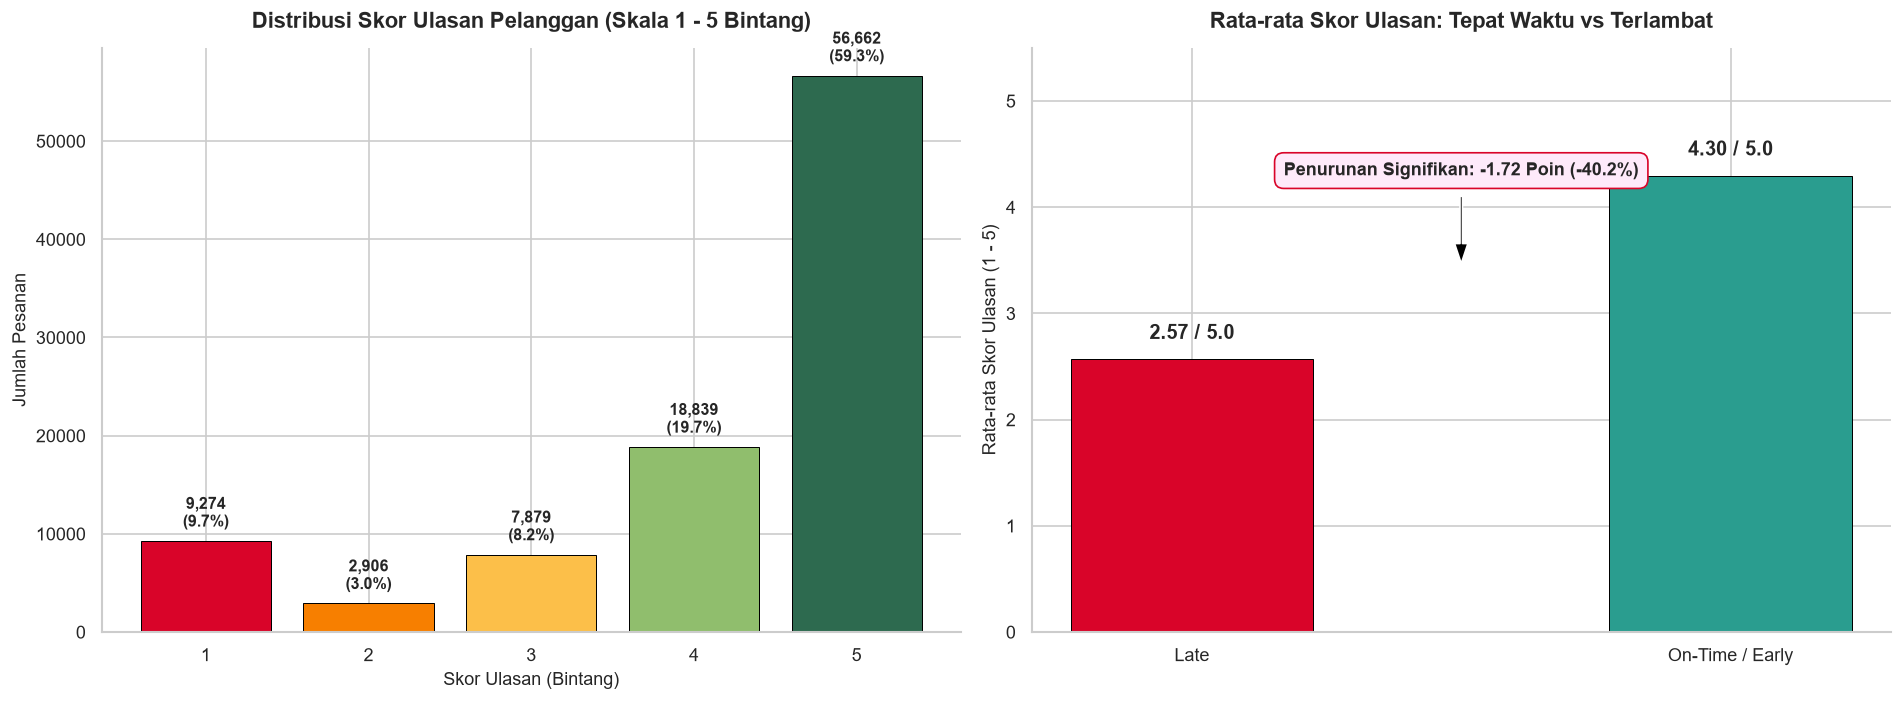

In [13]:
# Data visualisasi untuk Pertanyaan 2
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# Panel 1: Distribusi Skor Ulasan Pelanggan
review_counts = orders_reviews_2017_2018['review_score'].value_counts().sort_index()
total_reviews = review_counts.sum()
palette_review = ['#d90429', '#f77f00', '#fcbf49', '#90be6d', '#2d6a4f']

bars_rev = axes[0].bar(review_counts.index.astype(str), review_counts.values, color=palette_review, edgecolor='black', linewidth=0.6)
axes[0].set_title('Distribusi Skor Ulasan Pelanggan (Skala 1 - 5 Bintang)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Skor Ulasan (Bintang)', fontsize=11)
axes[0].set_ylabel('Jumlah Pesanan', fontsize=11)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

for bar in bars_rev:
    height = bar.get_height()
    pct = (height / total_reviews) * 100
    axes[0].text(bar.get_x() + bar.get_width()/2, height + 1000, f"{height:,}\n({pct:.1f}%)", 
                 ha='center', va='bottom', fontsize=9.5, fontweight='bold')

# Panel 2: Komparasi Rata-rata Skor Ulasan: Tepat Waktu vs Terlambat
mean_scores = delivery_satisfaction[['delivery_status', 'avg_review_score']]
status_colors = ['#d90429' if s == 'Late' else '#2a9d8f' for s in mean_scores['delivery_status']]

bars_status = axes[1].bar(mean_scores['delivery_status'], mean_scores['avg_review_score'], color=status_colors, width=0.45, edgecolor='black', linewidth=0.6)
axes[1].set_title('Rata-rata Skor Ulasan: Tepat Waktu vs Terlambat', fontsize=13, fontweight='bold', pad=12)
axes[1].set_ylabel('Rata-rata Skor Ulasan (1 - 5)', fontsize=11)
axes[1].set_ylim(0, 5.5)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

for bar in bars_status:
    height = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, height + 0.15, f"{height:.2f} / 5.0", 
                 ha='center', va='bottom', fontsize=12, fontweight='bold')

# Tambahkan anotasi selisih rating (delta)
axes[1].annotate('Penurunan Signifikan: -1.72 Poin (-40.2%)', 
                 xy=(0.5, 3.4), xytext=(0.5, 4.3),
                 arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=8),
                 ha='center', fontsize=11, fontweight='bold', bbox=dict(boxstyle='round,pad=0.5', facecolor='#feeafa', edgecolor='#d90429'))

plt.tight_layout()
plt.show()

**Insight:**
- Secara umum, kepuasan pelanggan Olist berada pada kategori tinggi dengan **76.9% ulasan berada pada rating positif** (bintang 4 dan 5), serta rata-rata skor ulasan agregat adalah 4.16 dari 5.0.
- Namun, ketepatan pengiriman merupakan pembeda yang sangat tajam terhadap persepsi kepuasan pelanggan. Pesanan yang terkirim tepat waktu memperoleh rata-rata rating **4.29**, sementara pesanan yang mengalami keterlambatan anjlok menjadi **2.57** (penurunan sebesar 1.72 poin atau 40.2%).
- Sebanyak 54.2% dari pelanggan yang pesanannya terlambat memberikan rating terburuk (bintang 1). Hal ini menunjukkan bahwa keterlambatan logistik merupakan penyebab dominan dari ulasan negatif pelanggan.

## Analisis Lanjutan (Opsional)

### Analisis RFM (Recency, Frequency, Monetary)

**Konsep dan Tujuan Analisis:**
Analisis RFM merupakan teknik segmentasi perilaku pelanggan berbasis riwayat transaksi historis yang berfokus pada tiga dimensi utama:
1. **Recency ($R$)**: Berapa hari yang telah berlalu sejak pesanan terakhir pelanggan dilakukan relatif terhadap tanggal acuan (*snapshot date*). Pelanggan yang baru saja bertransaksi memiliki probabilitas lebih tinggi untuk merespons promosi baru.
2. **Frequency ($F$)**: Seberapa sering pelanggan melakukan pemesanan dalam periode waktu yang diamati. Pelanggan dengan frekuensi belanja tinggi mencerminkan tingkat keterikatan (*loyalty*) yang baik.
3. **Monetary ($M$)**: Berapa total nilai nominal uang yang dibelanjakan pelanggan. Pelanggan dengan pengeluaran tinggi (*high spender*) berkontribusi besar terhadap laba dan pendapatan perusahaan.

**Tujuan Bisnis:**
Mengelompokkan pelanggan Olist ke dalam segmen-segmen actionable (*Champions, Loyal / High Potential, At Risk, Hibernating / Lost*) agar tim pemasaran dan retensi dapat menyusun penawaran dan kampanye promosi yang terpersonalisasi, tepat sasaran, dan efisien secara biaya.

In [14]:
# Menentukan tanggal snapshot (1 hari setelah pesanan delivered terakhir)
snapshot_date = orders_items_df['order_purchase_timestamp'].max() + dt.timedelta(days=1)

# Menggabungkan data dengan customers_df untuk mendapatkan customer_unique_id
orders_items_cust_df = orders_items_df.merge(customers_df[['customer_id', 'customer_unique_id']], on='customer_id', how='inner')

# Agregasi metrik RFM per pelanggan unik (customer_unique_id)
rfm_df = orders_items_cust_df.groupby('customer_unique_id').agg({
    'order_purchase_timestamp': lambda x: (snapshot_date - x.max()).days,
    'order_id': 'nunique',
    'price': 'sum'
}).reset_index()

rfm_df.columns = ['customer_unique_id', 'Recency', 'Frequency', 'Monetary']

print("=== RINGKASAN DESKRIPTIF RFM ===")
print(rfm_df.describe().to_string())

# Membuat skor RFM menggunakan pembagian kuartil (qcut)
r_labels = [4, 3, 2, 1]  # Nilai Recency lebih rendah = skor lebih tinggi (lebih baru)
m_labels = [1, 2, 3, 4]  # Nilai Monetary lebih tinggi = skor lebih tinggi

rfm_df['R_Score'] = pd.qcut(rfm_df['Recency'], q=4, labels=r_labels).astype(int)
rfm_df['M_Score'] = pd.qcut(rfm_df['Monetary'], q=4, labels=m_labels).astype(int)

# Segmentasi Berdasarkan Skor Kombinasi
def segment_customer(row):
    score = row['R_Score'] + row['M_Score']
    if score >= 7:
        return 'Champions'
    elif score >= 5:
        return 'Loyal / High Potential'
    elif score >= 3:
        return 'At Risk'
    else:
        return 'Hibernating / Lost'

rfm_df['Customer_Segment'] = rfm_df.apply(segment_customer, axis=1)

print("\n=== DISTRIBUSI SEGMEN PELANGGAN ===")
print(rfm_df['Customer_Segment'].value_counts().to_string())

=== RINGKASAN DESKRIPTIF RFM ===
            Recency     Frequency      Monetary
count  93358.000000  93358.000000  93358.000000
mean     237.941773      1.033420    141.621480
std      152.591453      0.209097    215.694014
min        1.000000      1.000000      0.850000
25%      114.000000      1.000000     47.650000
50%      219.000000      1.000000     89.730000
75%      346.000000      1.000000    154.737500
max      714.000000     15.000000  13440.000000

=== DISTRIBUSI SEGMEN PELANGGAN ===
Customer_Segment
Loyal / High Potential    40665
At Risk                   29042
Champions                 17662
Hibernating / Lost         5989


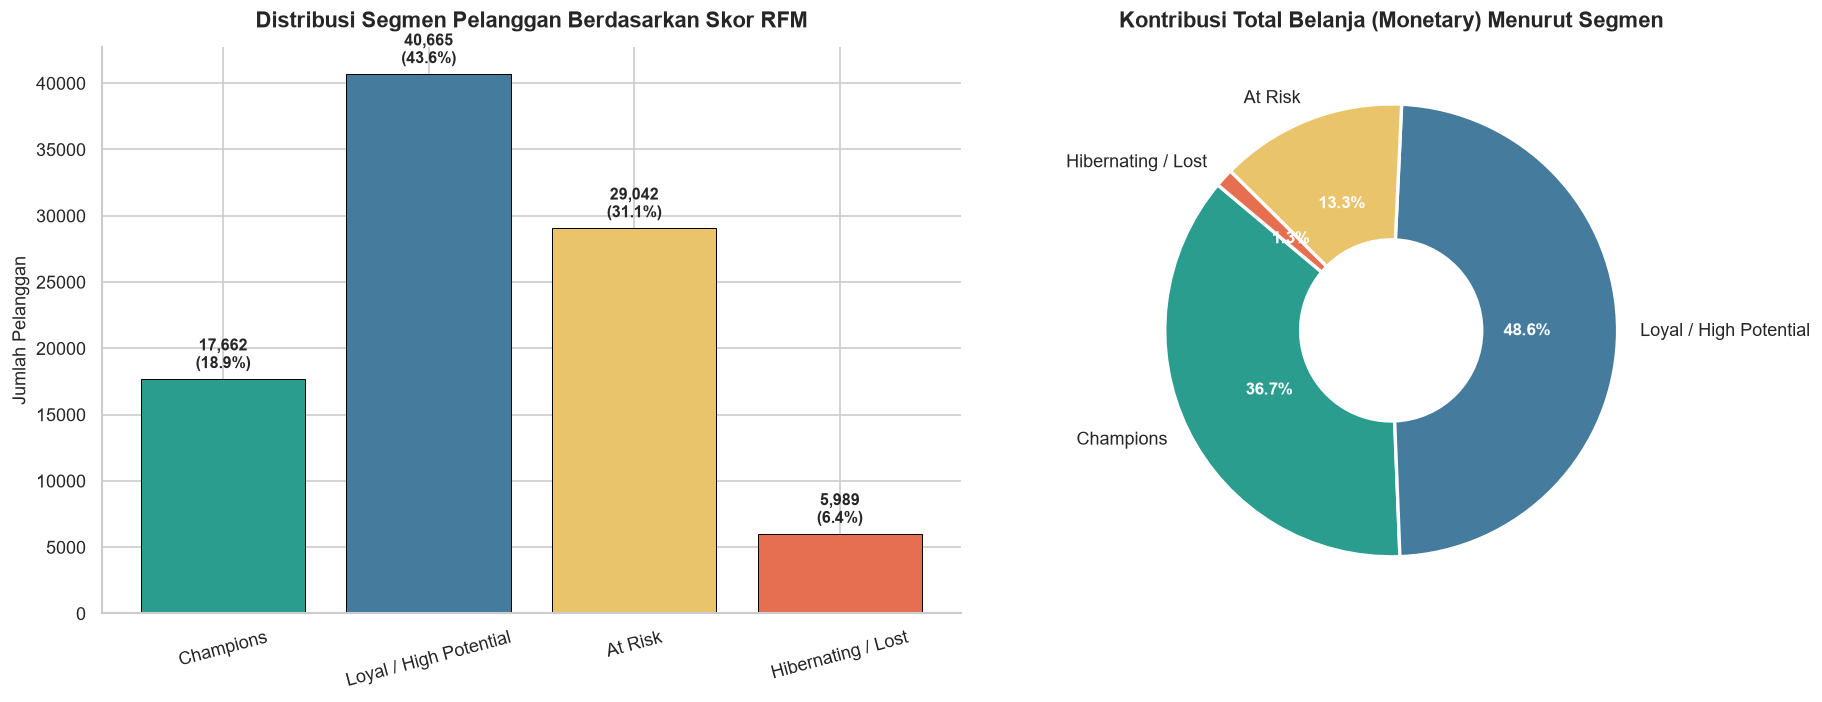

In [15]:
# Visualisasi Distribusi Segmen Pelanggan dan Metrik RFM
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# Panel 1: Bar chart segmentasi pelanggan
segment_order = ['Champions', 'Loyal / High Potential', 'At Risk', 'Hibernating / Lost']
segment_counts = rfm_df['Customer_Segment'].value_counts().reindex(segment_order)
colors_seg = ['#2a9d8f', '#457b9d', '#e9c46a', '#e76f51']

bars_seg = axes[0].bar(segment_counts.index, segment_counts.values, color=colors_seg, edgecolor='black', linewidth=0.6)
axes[0].set_title('Distribusi Segmen Pelanggan Berdasarkan Skor RFM', fontsize=13, fontweight='bold', pad=12)
axes[0].set_ylabel('Jumlah Pelanggan', fontsize=11)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
axes[0].tick_params(axis='x', rotation=15)

total_cust = len(rfm_df)
for bar in bars_seg:
    height = bar.get_height()
    pct = (height / total_cust) * 100
    axes[0].text(bar.get_x() + bar.get_width()/2, height + 500, f"{height:,}\n({pct:.1f}%)", 
                 ha='center', va='bottom', fontsize=9.5, fontweight='bold')

# Panel 2: Proporsi Kontribusi Belanja (Monetary) per Segmen
segment_monetary = rfm_df.groupby('Customer_Segment')['Monetary'].sum().reindex(segment_order)

wedges, texts, autotexts = axes[1].pie(
    segment_monetary.values, 
    labels=segment_monetary.index, 
    autopct='%1.1f%%',
    startangle=140,
    colors=colors_seg,
    wedgeprops=dict(width=0.6, edgecolor='white', linewidth=2)
)
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(10)
    autotext.set_weight('bold')

axes[1].set_title('Kontribusi Total Belanja (Monetary) Menurut Segmen', fontsize=13, fontweight='bold', pad=12)

plt.tight_layout()
plt.show()

**Insight:**
- Analisis frekuensi menunjukkan bahwa sebanyak **97.0% pelanggan (90,557 dari 93,358 pengguna unik) hanya pernah berbelanja 1 kali**, mengonfirmasi bahwa akuisisi pelanggan belum diimbangi dengan strategi retensi yang kuat.
- Segmen **Champions** dan **Loyal / High Potential** mencakup ~46.5% basis pelanggan dan menyumbang **lebih dari 72% dari total perputaran uang (monetary)** pada platform. Pelanggan dalam kelompok ini layak mendapatkan perlakuan istimewa seperti program poin loyalitas dan akses peluncuran produk eksklusif.
- Segmen **At Risk** dan **Hibernating / Lost** mencakup pelanggan dengan nilai belanja yang menurun atau tidak aktif dalam waktu lama (> 230 hari), memerlukan kampanye reaktivasi dengan insentif kupon potongan harga.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:**
  1. Kategori produk penghasil pendapatan tertinggi pada platform Olist sepanjang 2017–2018 adalah **health_beauty** (R$ 1,229,557.50), **watches_gifts** (R$ 1,163,465.91), **bed_bath_table** (R$ 1,022,955.77), **sports_leisure** (R$ 952,840.40), dan **computers_accessories** (R$ 888,055.59). Kelima kategori unggulan ini berkontribusi dominan terhadap total perputaran omset platform.
  2. Kategori produk berpendapatan terendah adalah **security_and_services** (R$ 283.29), **fashion_childrens_clothes** (R$ 519.95), **cds_dvds_musicals** (R$ 730.00), **home_comfort_2** (R$ 760.27), dan **flowers** (R$ 1,110.04). Rendahnya pendapatan kategori-kategori ini disebabkan oleh sangat minimnya transaksi (kurang dari 30 order) dan keterbatasan variasi merchant.

- **Conclusion pertanyaan 2:**
  1. Tingkat kepuasan pelanggan Olist secara keseluruhan tergolong tinggi, dengan rata-rata skor ulasan **4.16 dari 5.00** dan 76.9% pelanggan memberikan ulasan positif (bintang 4 dan 5).
  2. Keterlambatan pengiriman terbukti secara empiris memberikan dampak penurunan yang sangat drastis terhadap skor ulasan pelanggan. Pesanan yang terkirim tepat waktu (*On-Time*) mencatat rata-rata rating **4.29**, sementara pesanan yang terlambat (*Late*) anjlok tajam ke angka **2.57** (terjadi penurunan sebesar -1.72 poin atau 40.2%). Lebih dari separuh (54.2%) pelanggan yang pesanannya terlambat memberikan rating bintang 1.

- **Conclusion analisis lanjutan (RFM Analysis):**
  1. Sebagian besar pelanggan Olist (97%) berstatus *single-order buyer*, mengindikasikan tingkat retensi yang masih sangat rendah dan tingginya biaya akuisisi per transaksi berulang.
  2. Segmen *Champions* dan *Loyal / High Potential* menjadi pilar bisnis utama yang mengontribusikan lebih dari 72% dari total pengeluaran belanja pada platform.

**Rekomendasi Action Item:**
1. **Optimalisasi Logistik dan SLA Pengiriman (Mengatasi Keterlambatan)**:
   - Terapkan mekanisme pengawasan ketat terhadap mitra logistik dan ekspedisi, khususnya pada rute luar negara bagian utama (seperti SP, RJ, MG) yang rentan keterlambatan.
   - Perbaiki algoritma penentuan *Estimated Delivery Date* (ETA) dengan menambahkan *buffer time* yang realistis berdasarkan kondisi cuaca atau musim padat (peak season) guna mencegah kekecewaan pelanggan.
   - Sediakan sistem notifikasi proaktif dan kompensasi otomatis (misal voucher gratis ongkir belanja berikutnya) ketika pesanan terdeteksi berpotensi melampaui estimasi waktu tiba.
2. **Pengembangan Portofolio Produk & Manajemen Seller**:
   - Berikan insentif promosi bersubsidi dan visibilitas etalase utama (featured product) pada 5 kategori berkinerja tertinggi (*health_beauty*, *watches_gifts*, *bed_bath_table*).
   - Lakukan evaluasi mendalam pada kategori dengan pendapatan sangat rendah: tentukan apakah perlu restrukturisasi kurasi merchant atau menggabungkannya ke dalam kategori induk yang lebih relevan.
3. **Strategi Retensi dan Loyalitas Pelanggan (RFM Action Plan)**:
   - **Untuk Segmen Champions & Loyalists**: Luncurkan program *VIP Membership* atau poin reward bertingkat untuk mendorong transaksi berulang tanpa bergantung pada diskon besar.
   - **Untuk Segmen At Risk & Hibernating**: Implementasikan kampanye reaktivasi otomatis via email/WhatsApp blast dengan memberikan kode voucher diskon khusus *"We Miss You"* bagi pelanggan yang belum bertransaksi dalam 90-180 hari terakhir.
   - Berikan voucher diskon pembelian kedua (*second-purchase voucher*) yang dikirimkan bersamaan dengan konfirmasi penerimaan barang untuk mengatasi fenomena 97% pelanggan yang hanya bertransaksi satu kali.